## Activity 6.03: Creating a Stacked Bar Plot to Visualize Restaurant Performance


In this activity, we will use a stacked bar plot to visualize the performance of a restaurant. Due to a new law, you have to introduce a No Smoking Day. To make as few losses as possible, you want to visualize how many sales are made every day, categorized by smokers and non-smokers.

Use the dataset `tips` from Seaborn, which contains multiple entries of restaurant bills, and create a matrix where the elements contain the sum of the total bills for each day and smokers/non-smokers.


#### Import statements


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


#### Loading the dataset

The tutorial notes load Seaborn's built-in `tips` dataset with `sns.load_dataset('tips')`. We load the same dataset from a local CSV so the notebook is self-contained.


In [2]:
bills = pd.read_csv('tips.csv')


#### Creating a matrix of total bills by day and smoker status


In [3]:
days = ['Thur', 'Fri', 'Sat', 'Sun']
days_range = np.arange(len(days))
smoker = ['Yes', 'No']
bills_by_days = [bills[bills['day'] == day] for day in days]
bills_by_days_smoker = [[bills_by_days[day][bills_by_days[day]['smoker'] == s]
                         for s in smoker] for day in days_range]
total_by_days_smoker = [[bills_by_days_smoker[day][s]['total_bill'].sum()
                         for s in range(len(smoker))] for day in days_range]
totals = np.asarray(total_by_days_smoker)
totals


array([[ 326.24,  770.09],
       [ 252.2 ,   73.68],
       [ 893.62,  884.78],
       [ 458.28, 1168.88]])

#### Creating a stacked bar plot


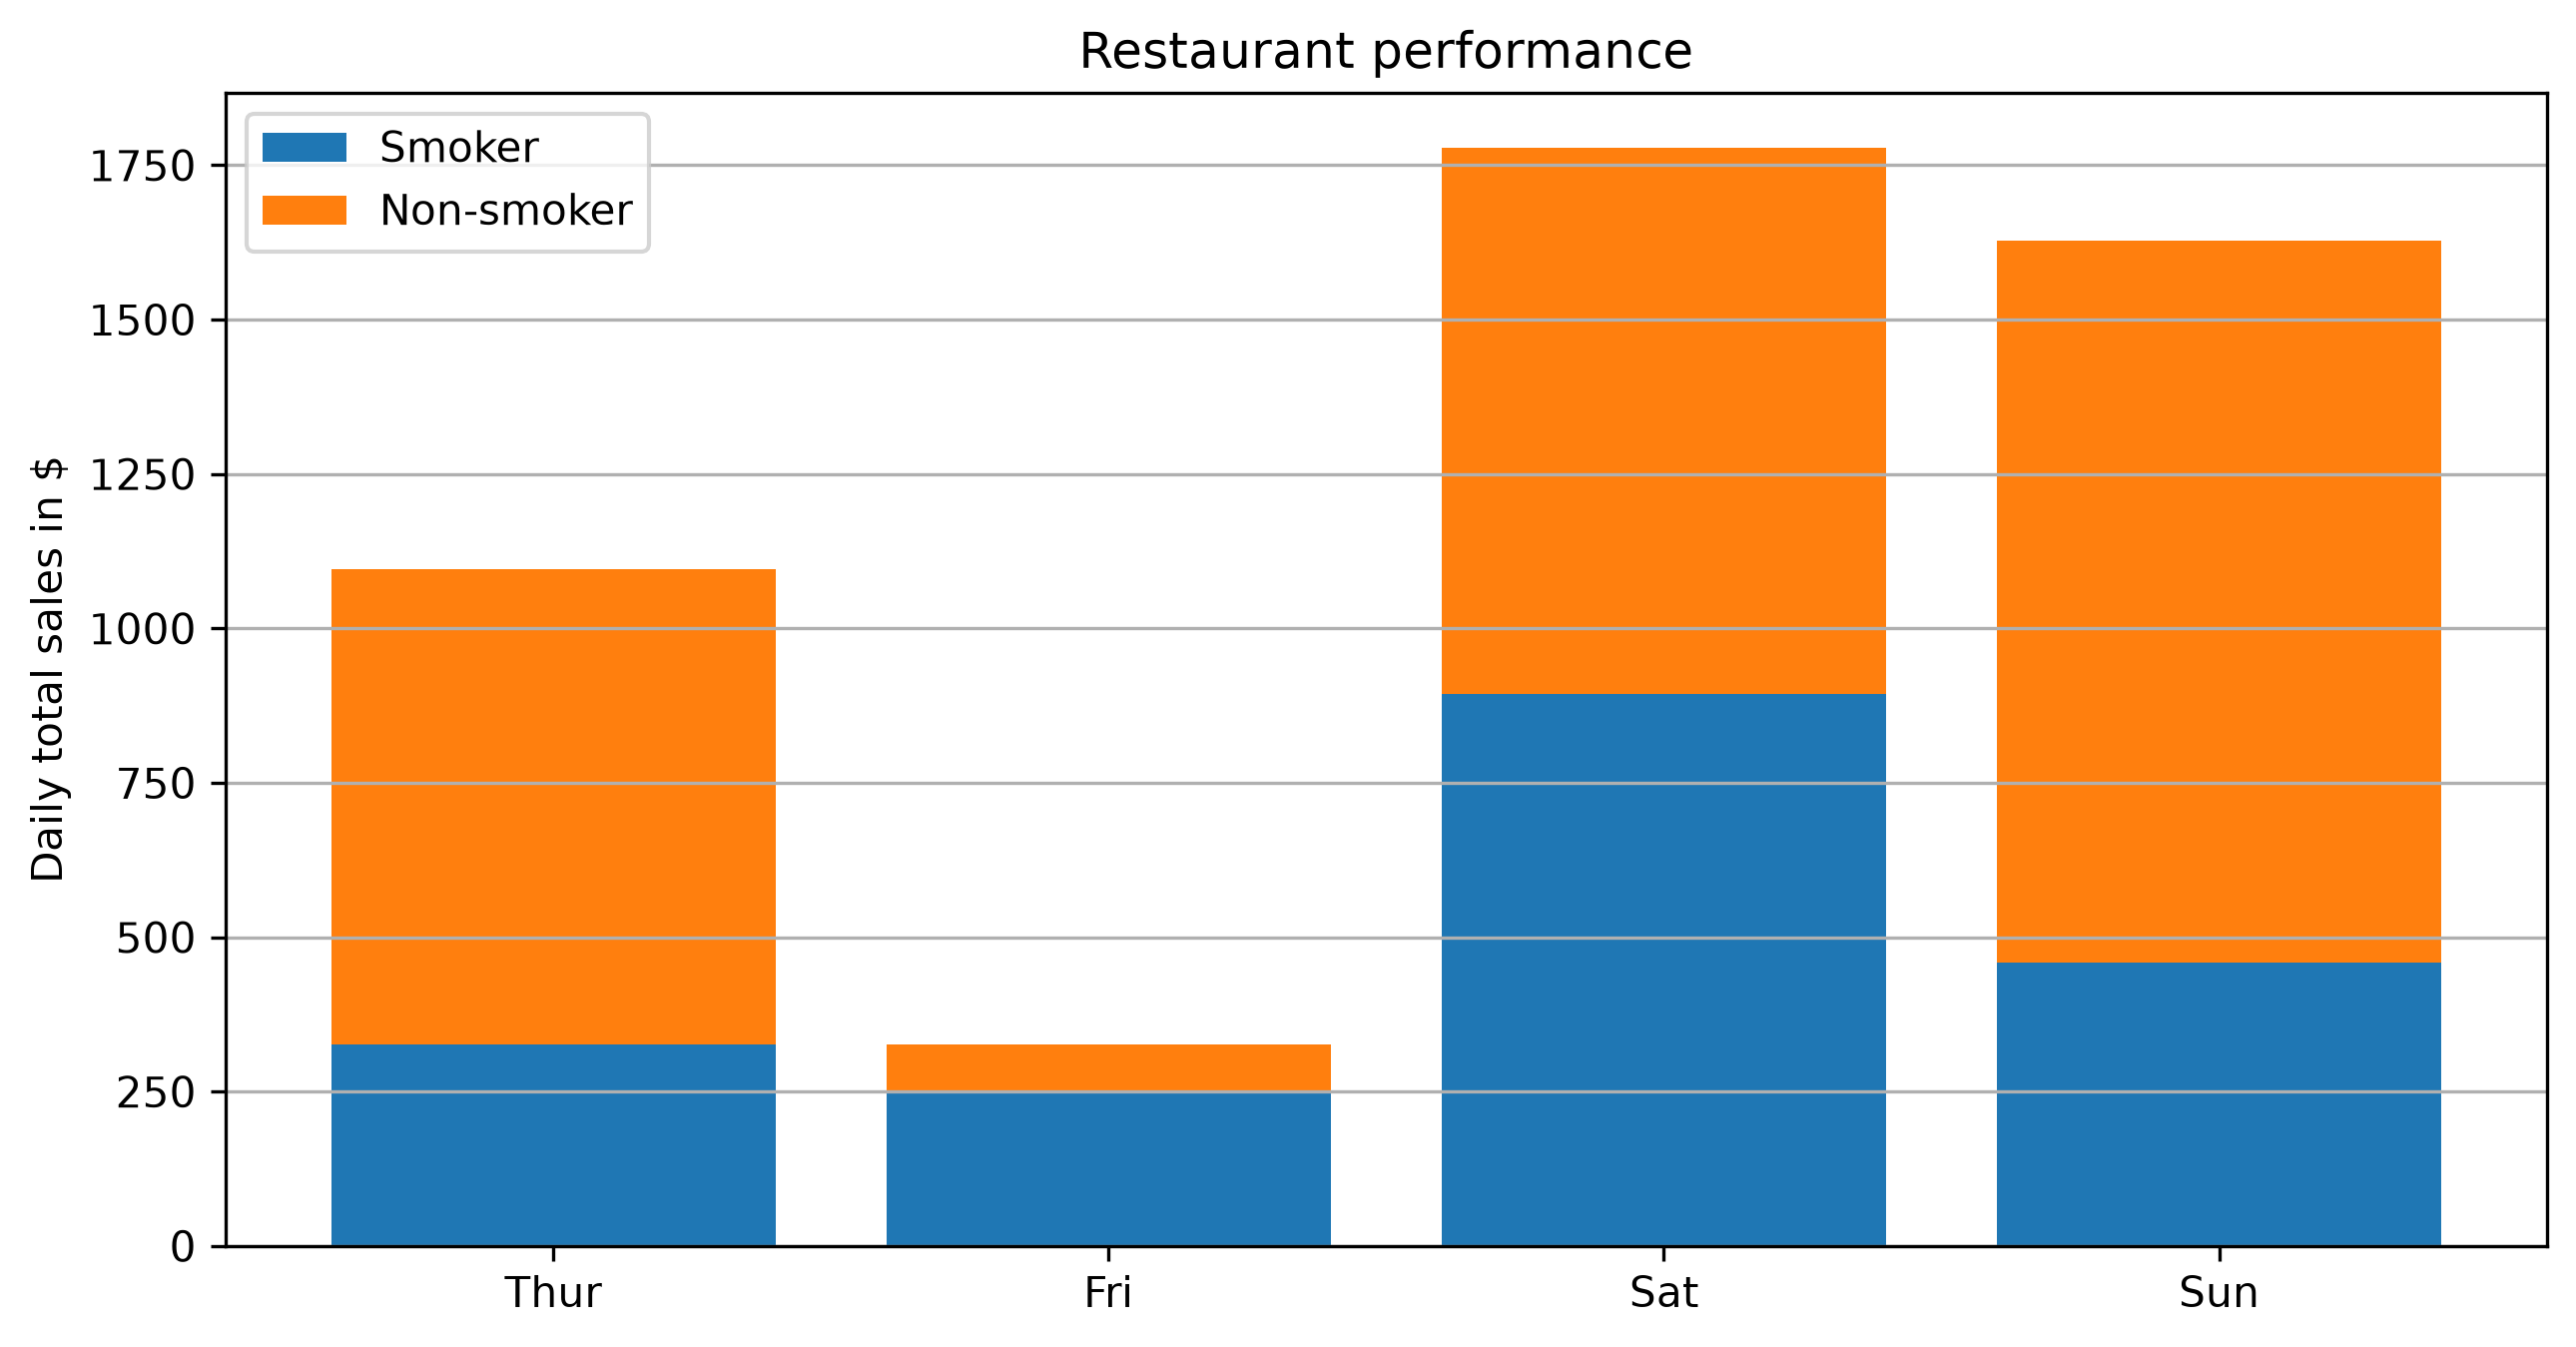

In [4]:
plt.figure(figsize=(10, 5), dpi=300)
plt.bar(days_range, totals[:, 0], label='Smoker')
plt.bar(days_range, totals[:, 1], bottom=totals[:, 0], label='Non-smoker')
plt.legend()
plt.xticks(days_range)
ax = plt.gca()
ax.set_xticklabels(days)
ax.yaxis.grid()
plt.ylabel('Daily total sales in $')
plt.title('Restaurant performance')
plt.show()
